# 歩行・ジョギングの分類とモデル評価 / Walking vs. Jogging: Classification and Evaluation

スマートフォンの加速度データから **Walking（歩行）と Jogging（ジョギング）** を判別します。
特徴量の可視化 → 人物単位のデータ分割 → 学習 → しきい値の検討 → 混同行列と評価指標、という順に進みます。

We classify walking and jogging from smartphone accelerometer data. We visualize features, split participants, train a model, explore the decision threshold, and interpret a confusion matrix and evaluation metrics.

**実行方法 / How to run:** Google Colab にこの ipynb をアップロードし、「ランタイム → すべてのセルを実行」を選びます。CPU で実行できます。追加ファイル・API キーは不要です。
Upload this notebook to Google Colab and select **Runtime → Run all**. A CPU runtime is sufficient. No additional files or API keys are required.

**陽性 / Positive class: Jogging = 1**、**陰性 / Negative class: Walking = 0**。
評価の単位は人でもセンサーの1点でもなく、**5秒間の測定区間（窓）**です。
Each prediction represents a **five-second window**, not a person or an individual sensor sample.

### データの出典 / Dataset attribution
[WISDM Activity Prediction v1.1](https://www.cis.fordham.edu/wisdm/dataset.php), WISDM Lab, Fordham University.
Jennifer R. Kwapisz, Gary M. Weiss and Samuel A. Moore (2010), *Activity Recognition using Cell Phone Accelerometers*, KDD-10 workshop.

公開された実測データから作成した特徴量と波形例を、このノートブックに同梱しています。合成データではありません。配布元の `readme.txt` も同梱し、実行時に保存します。末尾には公式の生データから特徴量を再作成するコードもあります。
This notebook embeds features and example signals derived from the published measurements, not synthetic data. The original `readme.txt` is included and saved during execution. Optional code at the end reproduces the features from the official raw data.

**追加 / Added:** 決定木・RBF SVMとの比較、共通軸での判定境界、3モデルの混同行列と評価表。
Comparison with a decision tree and RBF SVM, shared-axis decision regions, and evaluation tables and confusion matrices for all three models.


**交差検証 / Cross-validation:** developmentデータだけで人物単位の5分割GroupKFoldを実行し、各回の結果、平均・標準偏差、OOF混同行列を確認します。
Five-fold participant-grouped cross-validation on development data, with per-fold metrics, mean ± SD, and out-of-fold confusion matrices.


In [1]:
import io, json, base64, zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
    recall_score, f1_score, balanced_accuracy_score, classification_report,
    roc_auc_score, average_precision_score, RocCurveDisplay, PrecisionRecallDisplay)

# 表示設定と保存先 / Display settings and output folder.
plt.rcParams.update({'figure.dpi': 110, 'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False})
OUT = Path('classification_outputs')
OUT.mkdir(exist_ok=True)
SEED = 42

## 1. データを読む / Load the data

加速度の3軸から大きさ $a(t)=\sqrt{x(t)^2+y(t)^2+z(t)^2}$ を求め、5秒ごとに次の2特徴を取り出しました。

| 特徴 / Feature | 内容 / Meaning |
|---|---|
| `variation` | 加速度の大きさの標準偏差 / Standard deviation of acceleration magnitude |
| `frequency_hz` | 0.5–4 Hz の範囲で最も強い周波数成分 / Dominant spectral frequency in the 0.5–4 Hz band |

人物・活動の切り替わり、時刻の逆転、0.25秒を超える間隔で区切り、重ならない5秒窓を使います。時刻が無効な記録を除き、各窓は40点以上を必要とします。実際の測定間隔にはばらつきがあるため、時刻に基づいて20 Hzの時間軸に線形補間します。補間は新しい測定情報を増やすものではありません。

We split recordings at participant/activity changes, non-increasing timestamps, and gaps longer than 0.25 seconds. We use non-overlapping five-second windows with at least 40 samples, exclude invalid timestamps, and interpolate onto a 20 Hz time grid. Interpolation does not create new measurement information.

周波数は、平均を引いた信号にハニング窓をかけてFFTで求めます。主な周波数が、必ず歩数や足の接地の頻度に一致するわけではありません。また平均を引くだけで重力の影響が完全に除かれるわけではありません。
We subtract the mean, apply a Hann window, and use the FFT. The dominant frequency is not necessarily the step rate. Subtracting the mean does not completely remove the effects of gravity.

In [2]:
# @title 同梱データを読み込む / Load the embedded dataset
# 元の実測データから作成した特徴量 / Features derived from the original measurements.
PAYLOAD = "..."
with zipfile.ZipFile(io.BytesIO(base64.b64decode(PAYLOAD))) as bundle:
    data = pd.read_csv(bundle.open('features.csv'))
    examples = json.loads(bundle.read('examples.json'))
    preprocessing = json.loads(bundle.read('preprocessing.json'))
    (OUT / 'readme.txt').write_bytes(bundle.read('readme.txt'))
data['target'] = (data['activity'] == 'Jogging').astype(int)
FEATURES = ['variation', 'frequency_hz']
assert data[FEATURES].notna().all().all()
display(data.head())
display(data.groupby('activity').agg(windows=('target', 'size'), people=('person', 'nunique')))
print('Preprocessing summary:', preprocessing)

Preprocessing summary: {'valid_walk_jog_samples': 742504, 'malformed_records_all_activities': 11734, 'windows': 3510, 'people': 35}


,person,activity,segment,start_s,variation,frequency_hz,target
0,33,Jogging,1,0.0,5.109821,3.0,1
1,33,Jogging,4,0.0,5.244987,2.8,1
2,33,Jogging,4,5.0,4.806020,3.0,1
3,33,Jogging,7,0.0,4.873069,3.0,1
4,33,Jogging,7,5.0,5.183136,3.0,1


,windows,people
activity,,
Jogging,1114,29
Walking,2396,35


## 2. 人物ごとに分ける / Split by participant

同じ人の似た波形が学習とテストの両方に入ると、未知の人に対する性能を過大評価するおそれがあります。そこで、人物をおよそ60%・20%・20%に分けます。窓の数の割合は同じになりません。

- **Training:** モデルの重みと標準化を学習 / Fit model weights and feature scaling.
- **Validation:** しきい値などを検討 / Explore choices such as the threshold.
- **Test:** 選択を終えてから最終評価 / Evaluate only after making those choices.

We split participants, rather than individual windows, approximately 60/20/20. This evaluates performance on previously unseen people. Window counts need not follow the same proportions. This single split is a demonstration, not a guarantee of generalization to all users or devices.

In [3]:
# 人物IDは分割にだけ使い、入力特徴にはしない / Use participant IDs only for splitting.
split = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
development_idx, test_idx = next(split.split(data, groups=data.person))
development = data.iloc[development_idx]
split2 = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEED + 1)
train_idx, val_idx = next(split2.split(development, groups=development.person))
train = development.iloc[train_idx].copy()
val = development.iloc[val_idx].copy()
test = data.iloc[test_idx].copy()
assert set(train.person).isdisjoint(val.person)
assert set(train.person).isdisjoint(test.person)
assert set(val.person).isdisjoint(test.person)
assert all(part.target.nunique() == 2 for part in [train, val, test])
display(pd.DataFrame([
    {'split': name, 'people': part.person.nunique(), 'windows': len(part),
     'Walking': (part.target == 0).sum(), 'Jogging': part.target.sum()}
    for name, part in [('Training', train), ('Validation', val), ('Test', test)]]))

,split,people,windows,Walking,Jogging
0,Training,21,2257,1515,742
1,Validation,7,650,482,168
2,Test,7,603,399,204


## 3. 波形と特徴量を見る / Inspect signals and features

ここでは学習用の人物だけを表示します。波形は同じ人物の歩行とジョギングを比較します。「ジョギングでは変動が大きい」という傾向があっても、すべての区間に当てはまるとは限りません。
Only training participants are shown here. The signal examples compare walking and jogging for the same participant. A tendency toward larger variation while jogging need not hold for every window.

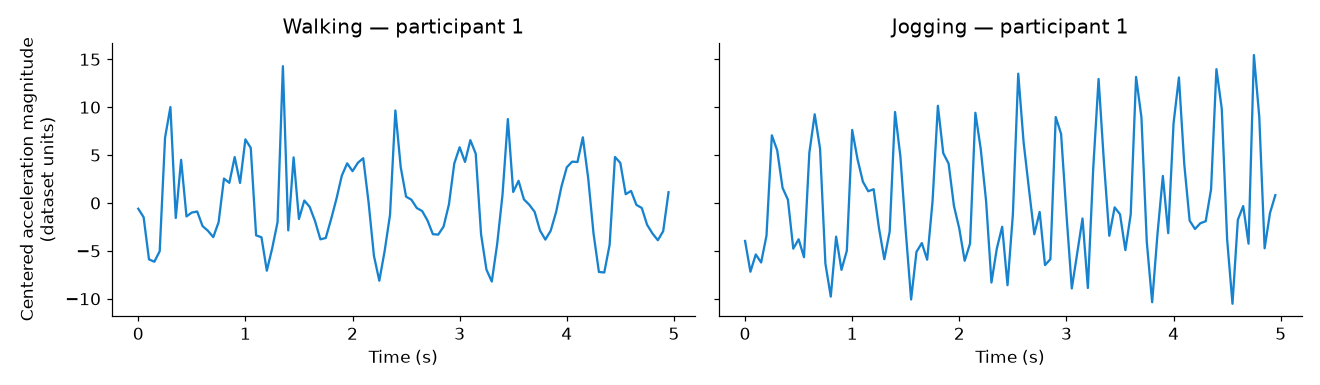

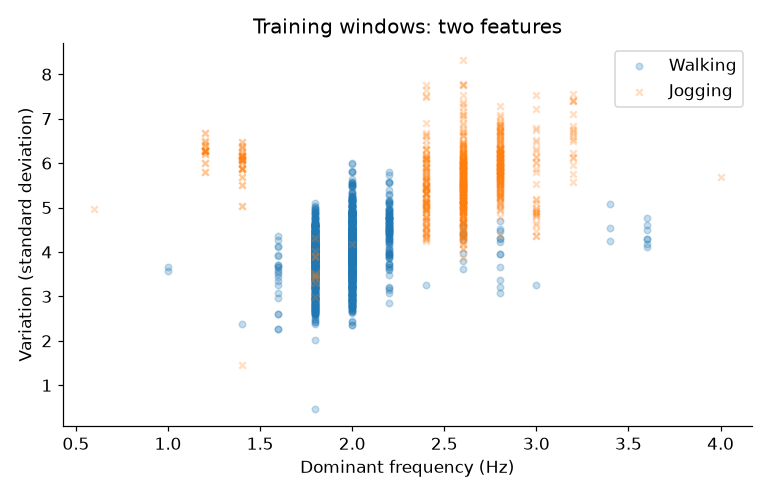

In [4]:
person = next(p for p in sorted(train.person.unique())
              if f'{p}_Walking' in examples and f'{p}_Jogging' in examples)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharex=True, sharey=True)
for ax, activity in zip(axes, ['Walking', 'Jogging']):
    ax.plot(np.arange(100) / 20, examples[f'{person}_{activity}'], color='#1783cf')
    ax.set(title=f'{activity} — participant {person}', xlabel='Time (s)')
axes[0].set_ylabel('Centered acceleration magnitude\n(dataset units)')
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 4.5))
for label, marker, name in [(0, 'o', 'Walking'), (1, 'x', 'Jogging')]:
    part = train[train.target == label]
    ax.scatter(part.frequency_hz, part.variation, marker=marker, alpha=0.25, s=18, label=name)
ax.set(xlabel='Dominant frequency (Hz)', ylabel='Variation (standard deviation)',
       title='Training windows: two features')
ax.legend()
fig.tight_layout()
plt.show()

## 4. ロジスティック回帰で学習する / Train logistic regression

今回は評価方法に集中するため、2特徴だけを使う単純なモデルを選びます。特徴量を標準化し、ジョギングである確率の推定値を出します。標準化の平均と標準偏差も、学習用データだけから求めます。

We use a simple model with two features to focus on evaluation. The pipeline learns scaling from training data only, then fits logistic regression. Its output is an estimated probability of jogging; that estimate is not guaranteed to be perfectly calibrated.

In [5]:
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=SEED))
model.fit(train[FEATURES], train.target)
val_probability = model.predict_proba(val[FEATURES])[:, 1]
print('Training complete. Positive class: Jogging (1).')

Training complete. Positive class: Jogging (1).


## 5. 混同行列を読む / Read the confusion matrix

この図では **行が実際のクラス、列が予測クラス**です。陽性を先に並べるので、配置は次のようになります。
Rows are actual classes and columns are predicted classes. With the positive class first:

| Actual / Predicted | Jogging (+) | Walking (−) |
|---|---|---|
| Jogging (+) | TP: 正しく検出 / Correct detection | FN: 見逃し / Miss |
| Walking (−) | FP: 誤検出 / False alarm | TN: 正しく除外 / Correct rejection |

| 指標 / Metric | 式 / Formula | 意味 / Interpretation |
|---|---|---|
| Accuracy / 正解率 | (TP + TN) / N | 全体の正解の割合 / Fraction correct overall |
| Precision / 適合率 | TP / (TP + FP) | ジョギングと予測した中で本当にジョギング / Fraction of predicted positives that are positive |
| Recall / 再現率 | TP / (TP + FN) | 実際のジョギングのうち検出できた割合 / Fraction of positives detected |
| Specificity / 特異度 | TN / (TN + FP) | 実際の歩行のうち歩行と判定した割合 / Fraction of negatives correctly rejected |
| F1 | 2TP / (2TP + FP + FN) | 適合率と再現率の調和平均 / Harmonic mean of precision and recall |
| Balanced accuracy | (Recall + Specificity) / 2 | 各クラスの再現率を同じ重みで平均 / Mean recall across the two classes |

N = TP + FN + FP + TN。分母がゼロの場合、この実装では0を表示しますが、数学的には未定義です。特に「ジョギングと一度も予測しない」場合の適合率に注意してください。
If a denominator is zero, this implementation reports 0 by convention; the ratio is mathematically undefined. This matters for precision when no windows are predicted as jogging.

In [6]:
def evaluate(y_true, y_pred):
    # 陽性を先に置く / Positive class first: [[TP, FN], [FP, TN]].
    cm = confusion_matrix(y_true, y_pred, labels=[1, 0])
    tp, fn, fp, tn = cm.ravel()
    safe_ratio = lambda a, b: float(a / b) if b else 0.0
    scores = {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred, zero_division=0),
        'Specificity': safe_ratio(tn, tn + fp),
        'F1': f1_score(y_true, y_pred, zero_division=0),
        'Balanced accuracy': balanced_accuracy_score(y_true, y_pred)}
    # 件数からの計算とライブラリの計算を照合 / Cross-check formulas against library results.
    assert np.isclose(scores['Precision'], safe_ratio(tp, tp + fp))
    assert np.isclose(scores['Recall'], safe_ratio(tp, tp + fn))
    assert np.isclose(scores['F1'], safe_ratio(2 * tp, 2 * tp + fp + fn))
    return cm, scores

def plot_matrix(cm, title, ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(5, 4))
    ax.imshow(cm, cmap='Blues', vmin=0)
    terms = [['TP', 'FN'], ['FP', 'TN']]
    for row in range(2):
        for col in range(2):
            ax.text(col, row, f'{terms[row][col]}\n{cm[row, col]:,}', ha='center', va='center',
                    fontsize=18, color='white' if cm[row, col] > cm.max() / 2 else '#102044')
    ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=['Jogging (+)', 'Walking (−)'],
           yticklabels=['Jogging (+)', 'Walking (−)'], xlabel='Predicted class',
           ylabel='Actual class', title=title)
    return ax

## 6. しきい値を変える / Change the threshold — validation data only

推定確率がしきい値以上ならジョギングと判定します。しきい値を下げると、検出する区間が増え、見逃しは減るか変わらず、誤検出は増えるか変わりません。適合率が必ず単調に変わるとは限りません。

A window is classified as jogging when its estimated probability is at least the threshold. Lower thresholds predict more positives: misses cannot increase and false alarms cannot decrease. Precision need not change monotonically.

下のセルの値を変更して、**このセルだけ**再実行してください。検討には validation のみを使います。実際の用途では、見逃しと誤検出のどちらが重要かを考えて決めます。
Change the value below and rerun **this cell only**. Use validation data for this exploration. Choose a threshold according to the relative importance of misses and false alarms.

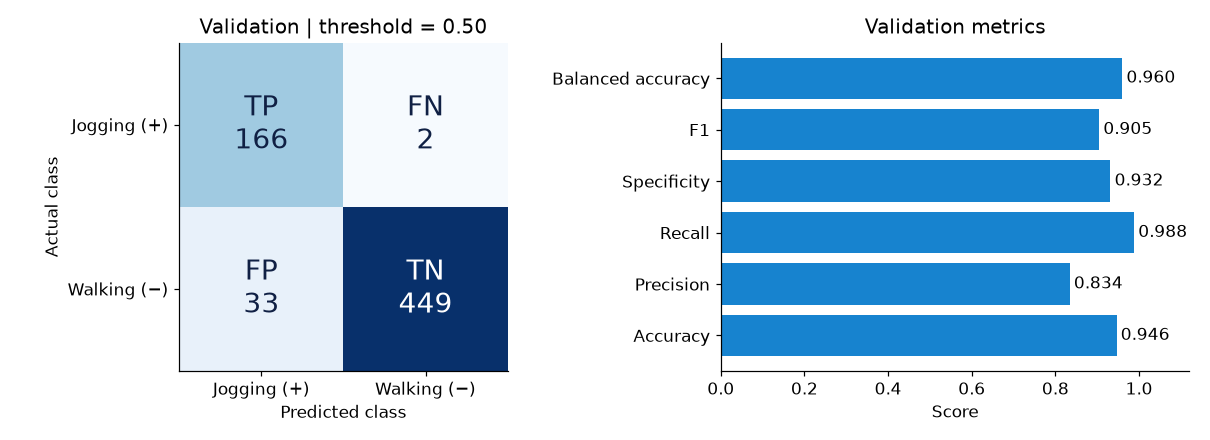

,Validation
Accuracy,0.9462
Precision,0.8342
Recall,0.9881
Specificity,0.9315
F1,0.9046
Balanced accuracy,0.9598


,threshold,FP,FN,Accuracy,Precision,Recall,Specificity,F1,Balanced accuracy
0,0.1,103,1,0.8400,0.6185,0.9940,0.7863,0.7626,0.8902
1,0.3,43,1,0.9323,0.7952,0.9940,0.9108,0.8836,0.9524
2,0.5,33,2,0.9462,0.8342,0.9881,0.9315,0.9046,0.9598
3,0.7,27,3,0.9538,0.8594,0.9821,0.9440,0.9167,0.9631
4,0.9,19,5,0.9631,0.8956,0.9702,0.9606,0.9314,0.9654


In [7]:
# @title 判定しきい値 / Decision threshold
threshold = 0.5 # @param {type:"slider", min:0.05, max:0.95, step:0.05}
val_prediction = (val_probability >= threshold).astype(int)
val_cm, val_scores = evaluate(val.target, val_prediction)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
plot_matrix(val_cm, f'Validation | threshold = {threshold:.2f}', axes[0])
axes[1].barh(list(val_scores), list(val_scores.values()), color='#1783cf')
axes[1].set(xlim=(0, 1.12), xlabel='Score', title='Validation metrics')
for i, value in enumerate(val_scores.values()):
    axes[1].text(value + 0.01, i, f'{value:.3f}', va='center')
fig.tight_layout()
plt.show()
display(pd.Series(val_scores, name='Validation').to_frame().round(4))

rows = []
for cutoff in [0.1, 0.3, 0.5, 0.7, 0.9]:
    cm, scores = evaluate(val.target, (val_probability >= cutoff).astype(int))
    rows.append({'threshold': cutoff, 'FP': cm[1, 0], 'FN': cm[0, 1], **scores})
display(pd.DataFrame(rows).round(4))

## 7. テストデータで最終評価する / Final evaluation on the test set

学習済みモデルと、validation で決めたしきい値をそのまま使います。テスト結果を見てしきい値を選び直すと、このデータは独立した最終評価には使えなくなります。

Use the trained model and the threshold chosen using validation data. If you change your choices based on test results, this test set no longer provides an independent final evaluation.

比較用に「すべて歩行」と答えるモデルも評価します。正解率だけでなく、ジョギングの再現率やF1にも注目してください。評価は窓ごとの集計なので、記録の長い人物の影響が大きくなります。参考として人物ごとの正解率も表示します。
We also evaluate an always-walking baseline. Compare recall and F1 as well as accuracy. Pooled window metrics give more influence to people with longer recordings; per-participant accuracy is shown as an additional view.

              precision    recall  f1-score   support

 Jogging (+)      0.969     0.931     0.950       204
 Walking (−)      0.966     0.985     0.975       399

    accuracy                          0.967       603
   macro avg      0.967     0.958     0.963       603
weighted avg      0.967     0.967     0.967       603



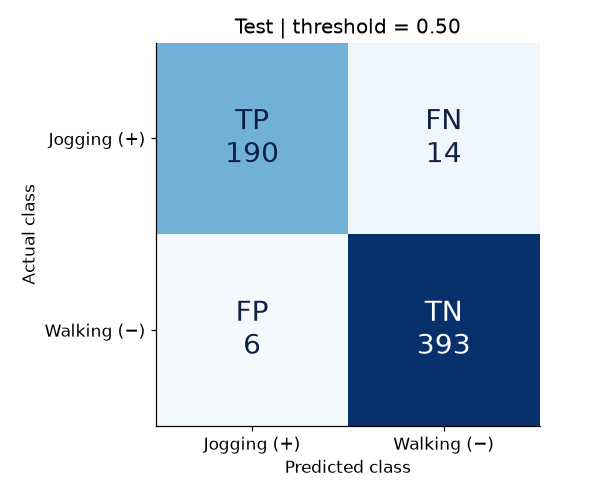

,Logistic regression,Always Walking
Accuracy,0.9668,0.6617
Precision,0.9694,0.0000
Recall,0.9314,0.0000
Specificity,0.9850,1.0000
F1,0.9500,0.0000
Balanced accuracy,0.9582,0.5000


,windows,accuracy
person,,
14,107,0.944
16,41,1.000
20,58,1.000
22,78,1.000
25,84,0.857
27,47,0.957
31,188,1.000


In [8]:
test_probability = model.predict_proba(test[FEATURES])[:, 1]
test_prediction = (test_probability >= threshold).astype(int)
test_cm, test_scores = evaluate(test.target, test_prediction)
_, baseline_scores = evaluate(test.target, np.zeros(len(test), dtype=int))
fig, ax = plt.subplots(figsize=(5.5, 4.5))
plot_matrix(test_cm, f'Test | threshold = {threshold:.2f}', ax)
fig.tight_layout()
fig.savefig(OUT / 'test_confusion_matrix.png', dpi=180, bbox_inches='tight')
plt.show()
comparison = pd.DataFrame({'Logistic regression': test_scores, 'Always Walking': baseline_scores})
display(comparison.round(4))
print(classification_report(test.target, test_prediction, labels=[1, 0],
      target_names=['Jogging (+)', 'Walking (−)'], digits=3, zero_division=0))

predictions = test.copy()
predictions['jogging_probability'] = test_probability
predictions['prediction'] = test_prediction
predictions['correct'] = (test.target.to_numpy() == test_prediction)
display(predictions.groupby('person').agg(windows=('target', 'size'), accuracy=('correct', 'mean')).round(3))
comparison.to_csv(OUT / 'test_metrics.csv')
predictions.to_csv(OUT / 'test_predictions.csv', index=False)
pd.DataFrame(test_cm, index=['Actual Jogging', 'Actual Walking'],
             columns=['Predicted Jogging', 'Predicted Walking']).to_csv(OUT / 'test_confusion_matrix.csv')

## 8. しきい値全体で見る / Look across thresholds: ROC and precision–recall curves

ROC は横軸が偽陽性率 FP/(FP+TN)、縦軸が再現率です。PR 曲線は横軸が再現率、縦軸が適合率です。どちらも一つのしきい値での性能だけでなく、しきい値を変えたときの関係を示します。

ROC plots false positive rate against recall. The precision–recall (PR) curve plots recall against precision. Both summarize behavior across thresholds.

ROC-AUC と Average Precision（AP）も表示します。AP はPR曲線を要約する指標で、単純な台形則の面積と同一ではありません。AP は陽性の割合にも影響されます。これらも単独でモデルの良さを決めるものではありません。
We report ROC-AUC and average precision (AP). AP summarizes the PR curve and is not the same as a simple trapezoidal area. It depends on positive-class prevalence. Neither score alone determines whether a model is suitable for its intended use.

ROC-AUC: 0.9868
Average precision: 0.9819


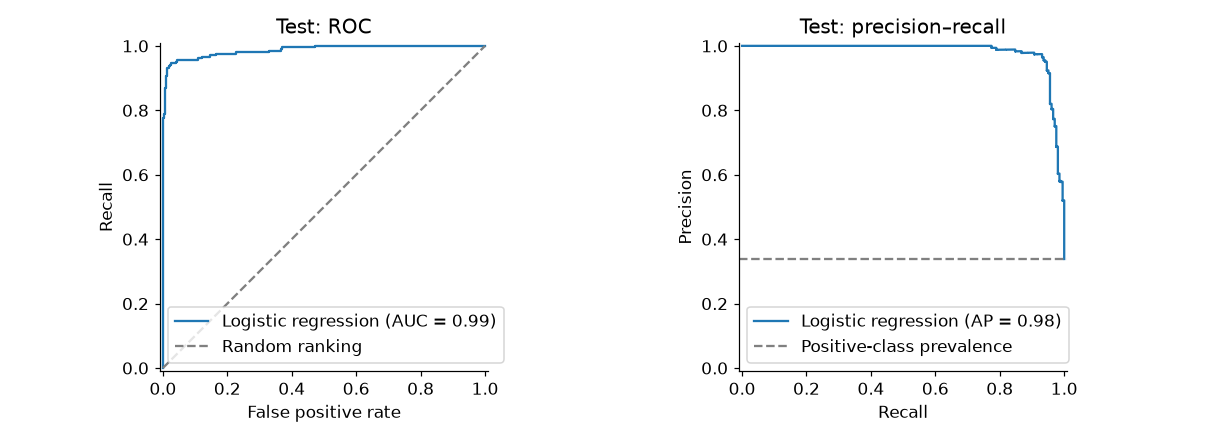

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
RocCurveDisplay.from_predictions(test.target, test_probability, ax=axes[0], name='Logistic regression')
axes[0].plot([0, 1], [0, 1], '--', color='gray', label='Random ranking')
axes[0].set(title='Test: ROC', xlabel='False positive rate', ylabel='Recall')
axes[0].legend()
PrecisionRecallDisplay.from_predictions(test.target, test_probability, ax=axes[1], name='Logistic regression')
axes[1].axhline(test.target.mean(), ls='--', color='gray', label='Positive-class prevalence')
axes[1].set(title='Test: precision–recall', xlabel='Recall', ylabel='Precision')
axes[1].legend()
fig.tight_layout()
fig.savefig(OUT / 'test_roc_pr.png', dpi=180, bbox_inches='tight')
plt.show()
print(f'ROC-AUC: {roc_auc_score(test.target, test_probability):.4f}')
print(f'Average precision: {average_precision_score(test.target, test_probability):.4f}')

## 9. 決定木・SVMとの比較 / Compare logistic regression, a decision tree, and SVM

ここからは3モデルを**同じ2特徴、同じ人物単位の分割**で比較します。ここまでのロジスティック回帰のしきい値実験とは分け、比較では各モデルの標準の `predict` を使用します。
We compare three models using **the same two features and participant splits**. This comparison uses each model's standard `predict` rule, independently of the earlier logistic-regression threshold experiment.

| モデル / Model | 固定した設定 / Fixed settings | 判定 / Decision rule |
|---|---|---|
| Logistic regression | StandardScaler; C=1 | Probability threshold 0.5 |
| Decision tree | max_depth=4; min_samples_leaf=10 | Majority class in a leaf |
| RBF SVM | StandardScaler; C=1; gamma=scale | Decision score threshold 0 |

決定木は特徴量をしきい値で順に分割します。RBF SVMは曲線状の境界を扱えます。SVMのスコアは確率ではありません。ROC・PR曲線は確率以外の連続スコアでも計算できます。
A decision tree splits features at successive thresholds. RBF SVM can learn curved boundaries. Its decision score is **not a probability**, but continuous scores can still be used for ROC and PR curves.

設定は教材用に固定し、テスト結果に合わせた調整はしません。まずvalidationの比較を示し、最後にtestの結果をまとめます。これは同じ保持データでの教材上の比較です。結果を見てモデルや設定を選び直す場合は、最終確認用に新しい未使用データを用意してください。
Settings are fixed for teaching and are not tuned to test results. Validation results are shown first, followed by test results. This is a teaching comparison on the existing holdout. If you use these results to revise model choices, reserve fresh, unused data for a final assessment.

In [10]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC

# 全モデルを同じ学習データで学習 / Fit all models on the same training data.
models = {
    'Logistic regression': make_pipeline(StandardScaler(),
        LogisticRegression(C=1.0, max_iter=1000, random_state=SEED)),
    'Decision tree': DecisionTreeClassifier(max_depth=4, min_samples_leaf=10, random_state=SEED),
    'RBF SVM': make_pipeline(StandardScaler(), SVC(C=1.0, kernel='rbf', gamma='scale')),
}

def ranking_score(estimator, features):
    # SVMは確率ではなく決定スコアを使う / Use SVM decision scores, not probabilities.
    if hasattr(estimator, 'decision_function'):
        return estimator.decision_function(features)
    return estimator.predict_proba(features)[:, 1]

validation_rows = []
for name, estimator in models.items():
    estimator.fit(train[FEATURES], train.target)
    predicted = estimator.predict(val[FEATURES])
    cm, scores = evaluate(val.target, predicted)
    validation_rows.append({'Model': name, **scores, 'FP': int(cm[1, 0]), 'FN': int(cm[0, 1])})
validation_comparison = pd.DataFrame(validation_rows).set_index('Model')
display(validation_comparison.round(4))
validation_comparison.to_csv(OUT / 'model_comparison_validation.csv')

,Accuracy,Precision,Recall,Specificity,F1,Balanced accuracy,FP,FN
Model,,,,,,,,
Logistic regression,0.9462,0.8342,0.9881,0.9315,0.9046,0.9598,33,2
Decision tree,0.9615,0.8783,0.9881,0.9523,0.9300,0.9702,23,2
RBF SVM,0.9815,0.9382,0.9940,0.9772,0.9653,0.9856,11,1


### 同じ特徴空間で境界を見る / Compare boundaries in the same feature space

背景は予測するクラス、○は歩行、×はジョギングです。点は学習用データだけです。決定木の階段状の境界、線形モデルの直線、SVMの曲線を比較してください。境界が複雑なほど良いとは限りません。
Background shading indicates the predicted class. Circles represent walking and crosses represent jogging. Only training data are plotted. Compare the tree's stepped boundary, the linear model's straight boundary, and SVM's curved boundary. Greater complexity does not necessarily mean better generalization.

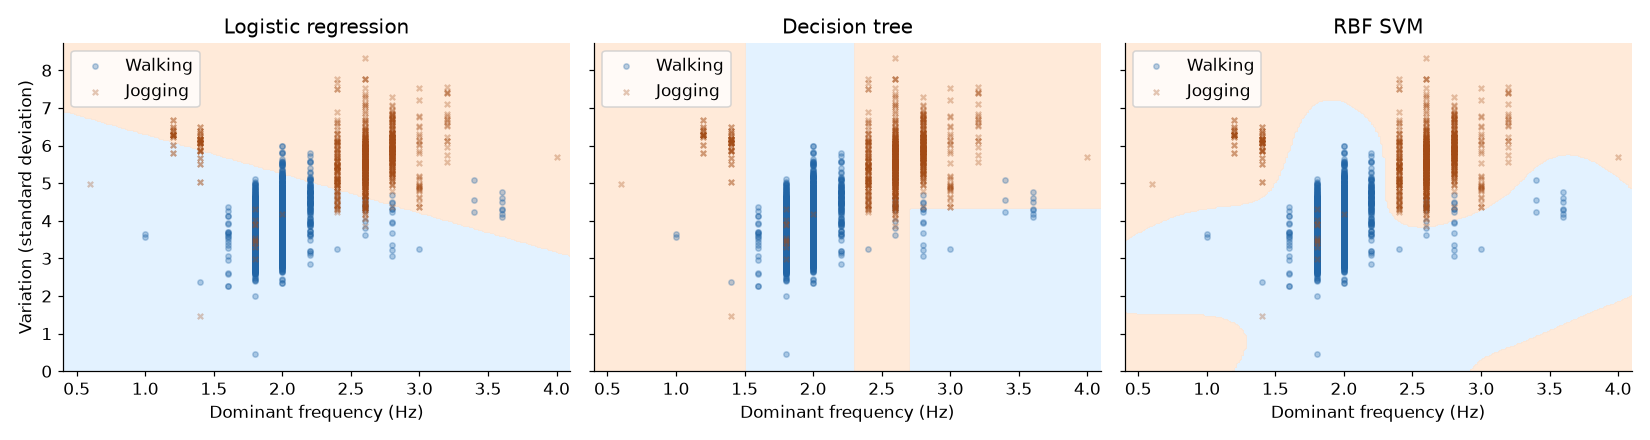

In [11]:
# 全モデルで共通の軸とグリッド / Use identical axes and grids for all models.
frequency_grid, variation_grid = np.meshgrid(
    np.linspace(0.4, 4.1, 220),
    np.linspace(0, train.variation.max() * 1.05, 220))
grid = pd.DataFrame({'variation': variation_grid.ravel(),
                     'frequency_hz': frequency_grid.ravel()})
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True, sharey=True)
for ax, (name, estimator) in zip(axes, models.items()):
    regions = estimator.predict(grid).reshape(frequency_grid.shape)
    ax.contourf(frequency_grid, variation_grid, regions, levels=[-0.5, 0.5, 1.5],
                colors=['#dcefff', '#ffe5d0'], alpha=0.8)
    for label, marker, color, activity in [(0, 'o', '#2165a6', 'Walking'),
                                          (1, 'x', '#a34b15', 'Jogging')]:
        subset = train[train.target == label]
        ax.scatter(subset.frequency_hz, subset.variation, marker=marker, c=color,
                   s=12, alpha=0.3, label=activity)
    ax.set(title=name, xlabel='Dominant frequency (Hz)')
    ax.legend(loc='upper left')
axes[0].set_ylabel('Variation (standard deviation)')
fig.tight_layout()
fig.savefig(OUT / 'model_comparison_boundaries.png', dpi=180, bbox_inches='tight')
plt.show()

### 人物単位の5分割交差検証 / Five-fold cross-validation by participant

ここでは、先ほどの **training と validation を合わせた development データ**を5分割します。最終testの人物は一切含めません。各回で4分割を学習に、残り1分割を評価に使い、評価に使う分割を交代します。全モデルが同じ分割を使います。
We split the **development set (the earlier training and validation sets combined)** into five folds. Final-test participants are excluded. Each round trains on four folds and evaluates on the remaining fold. All models use exactly the same folds.

`GroupKFold` に人物IDを渡すので、同じ人の窓が同じ回の学習と評価に混ざりません。1点ずつランダムに分ける方法との違いに注目してください。ここでは互換性と再現性のため、シャッフルしないGroupKFoldを使います。
Passing participant IDs to `GroupKFold` prevents a person's windows from appearing in both training and evaluation within a fold. Unlike random window splitting, this assesses unseen participants. We use unshuffled GroupKFold for compatibility and reproducibility.

毎回モデルを新しく作り、標準化もその回の学習データだけで学習します。決定木とSVMの設定は先ほどと同じで、交差検証中には変更しません。しきい値も各モデルの標準の判定規則です。
Each round fits a fresh model, including any scaling, using that fold's training data only. Model settings remain fixed, and each model uses its standard decision rule.

**実験 / Experiment:** `n_splits` を3、5、7に変更して、この交差検証の3つのコードセルを再実行すると、分割数による変化を確認できます。既定値は5です。分割数を変えた結果は独立した追加データによる検証ではありません。
Change `n_splits` to 3, 5, or 7 and rerun the three cross-validation code cells to explore the effect of fold count. The default is five. Repeating the experiment with another fold count does not provide independent new data.

In [12]:
# @title 交差検証の分割数 / Number of cross-validation folds
n_splits = 5 # @param [3, 5, 7] {type:"raw"}
from sklearn.model_selection import GroupKFold
from sklearn.base import clone

cv_data = development.reset_index(drop=True).copy()
assert set(cv_data.person).isdisjoint(test.person)
assert 2 <= n_splits <= cv_data.person.nunique()
cv = GroupKFold(n_splits=n_splits)
folds = list(cv.split(cv_data[FEATURES], cv_data.target, groups=cv_data.person))
fold_details = []
cv_rows = []
oof_prediction = {name: np.full(len(cv_data), -1, dtype=int) for name in models}
seen = np.zeros(len(cv_data), dtype=int)
oof_fold = np.zeros(len(cv_data), dtype=int)

for fold, (fit_idx, valid_idx) in enumerate(folds, start=1):
    fit_part, valid_part = cv_data.iloc[fit_idx], cv_data.iloc[valid_idx]
    # 人物の重複とクラスの存在を確認 / Check participant separation and class availability.
    assert set(fit_part.person).isdisjoint(valid_part.person)
    assert fit_part.target.nunique() == 2 and valid_part.target.nunique() == 2
    seen[valid_idx] += 1
    oof_fold[valid_idx] = fold
    fold_details.append({'Fold': fold, 'Train people': fit_part.person.nunique(),
        'Validation people': valid_part.person.nunique(), 'Train windows': len(fit_part),
        'Validation windows': len(valid_part), 'Walking': int((valid_part.target == 0).sum()),
        'Jogging': int(valid_part.target.sum()),
        'Validation participant IDs': ', '.join(map(str, sorted(valid_part.person.unique())))})
    for name, template in models.items():
        # 学習済みモデルの状態を引き継がない / Clone settings without retaining fitted state.
        estimator = clone(template)
        estimator.fit(fit_part[FEATURES], fit_part.target)
        predicted = estimator.predict(valid_part[FEATURES])
        score = ranking_score(estimator, valid_part[FEATURES])
        cm, metrics = evaluate(valid_part.target, predicted)
        cv_rows.append({'Model': name, 'Fold': fold, **metrics,
            'ROC-AUC': roc_auc_score(valid_part.target, score),
            'Average precision': average_precision_score(valid_part.target, score),
            'TP': int(cm[0, 0]), 'FN': int(cm[0, 1]), 'FP': int(cm[1, 0]), 'TN': int(cm[1, 1])})
        oof_prediction[name][valid_idx] = predicted

# 各窓は評価用としてちょうど1回使われる / Every window is held out exactly once.
assert np.all(seen == 1)
assert all(np.all(values >= 0) for values in oof_prediction.values())
fold_table = pd.DataFrame(fold_details)
cv_results = pd.DataFrame(cv_rows)
display(fold_table)
display(cv_results.round(4))
print(f'Completed: {n_splits} folds x {len(models)} models. No final-test participants used.')
fold_table.to_csv(OUT / 'cv_fold_assignment.csv', index=False)
cv_results.to_csv(OUT / 'cv_per_fold_metrics.csv', index=False)

Completed: 5 folds x 3 models. No final-test participants used.


,Fold,Train people,Validation people,Train windows,Validation windows,Walking,Jogging,Validation participant IDs
0,1,23,5,2331,576,341,235,"7, 10, 15, 19, 36"
1,2,23,5,2347,560,368,192,"8, 11, 24, 29, 32"
2,3,22,6,2304,603,437,166,"1, 5, 6, 12, 21, 33"
3,4,22,6,2313,594,439,155,"2, 4, 9, 13, 28, 35"
4,5,22,6,2333,574,412,162,"3, 17, 18, 23, 26, 34"


,Model,Fold,Accuracy,Precision,Recall,Specificity,F1,Balanced accuracy,ROC-AUC,Average precision,TP,FN,FP,TN
0,Logistic regression,1,0.9219,0.9948,0.8128,0.9971,0.8946,0.9049,0.9502,0.9586,191,44,1,340
1,Decision tree,1,0.8385,0.9863,0.6128,0.9941,0.7559,0.8035,0.9726,0.9630,144,91,2,339
2,RBF SVM,1,0.9670,0.9865,0.9319,0.9912,0.9584,0.9616,0.9871,0.9795,219,16,3,338
3,Logistic regression,2,0.9286,0.9578,0.8281,0.9810,0.8883,0.9046,0.9899,0.9812,159,33,7,361
4,Decision tree,2,0.9768,0.9543,0.9792,0.9755,0.9666,0.9774,0.9967,0.9887,188,4,9,359
5,RBF SVM,2,0.9732,0.9275,1.0000,0.9592,0.9624,0.9796,0.9906,0.9787,192,0,15,353
6,Logistic regression,3,0.9436,0.8474,0.9699,0.9336,0.9045,0.9518,0.9908,0.9785,161,5,29,408
7,Decision tree,3,0.9934,0.9821,0.9940,0.9931,0.9880,0.9936,0.9998,0.9994,165,1,3,434
8,RBF SVM,3,0.9900,0.9938,0.9699,0.9977,0.9817,0.9838,0.9995,0.9988,161,5,1,436
9,Logistic regression,4,0.9949,1.0000,0.9806,1.0000,0.9902,0.9903,0.9997,0.9991,152,3,0,439


#### 平均とばらつきを比較する / Compare means and variability

各回の評価値を同じ重みで平均し、標本標準偏差（ddof=1）を表示します。標準偏差は分割によるばらつきの記述であり、信頼区間ではありません。各回で学習データが重なるため、独立した5回の実験でもありません。
We report equally weighted fold means and sample standard deviations (ddof=1). Standard deviations describe variation across folds; they are not confidence intervals. Training sets overlap, so the folds are not five independent experiments.

この交差検証は、固定した設定の性能を比較する実験です。モデルや設定の選択に結果を使う場合、選んだモデルの最終性能は未使用のテストデータで確認します。
This experiment compares fixed model settings. If CV results guide model or parameter selection, assess the chosen model on an unused test set.

                            Accuracy        Precision           Recall               F1
Model                                                                                  
Logistic regression  0.9379 ± 0.0354  0.9144 ± 0.1006  0.9022 ± 0.0783  0.9034 ± 0.0546
Decision tree        0.9569 ± 0.0668  0.9714 ± 0.0227  0.9135 ± 0.1683  0.9336 ± 0.1004
RBF SVM              0.9826 ± 0.0131  0.9754 ± 0.0291  0.9742 ± 0.0281  0.9743 ± 0.0168


,Accuracy,Precision,Recall,Specificity,F1,Balanced accuracy,ROC-AUC,Average precision
Model,,,,,,,,
Logistic regression,0.9379 ± 0.0354,0.9144 ± 0.1006,0.9022 ± 0.0783,0.9610 ± 0.0463,0.9034 ± 0.0546,0.9316 ± 0.0385,0.9747 ± 0.0261,0.9563 ± 0.0535
Decision tree,0.9569 ± 0.0668,0.9714 ± 0.0227,0.9135 ± 0.1683,0.9873 ± 0.0107,0.9336 ± 0.1004,0.9504 ± 0.0827,0.9912 ± 0.0117,0.9862 ± 0.0153
RBF SVM,0.9826 ± 0.0131,0.9754 ± 0.0291,0.9742 ± 0.0281,0.9872 ± 0.0164,0.9743 ± 0.0168,0.9807 ± 0.0137,0.9940 ± 0.0056,0.9888 ± 0.0102


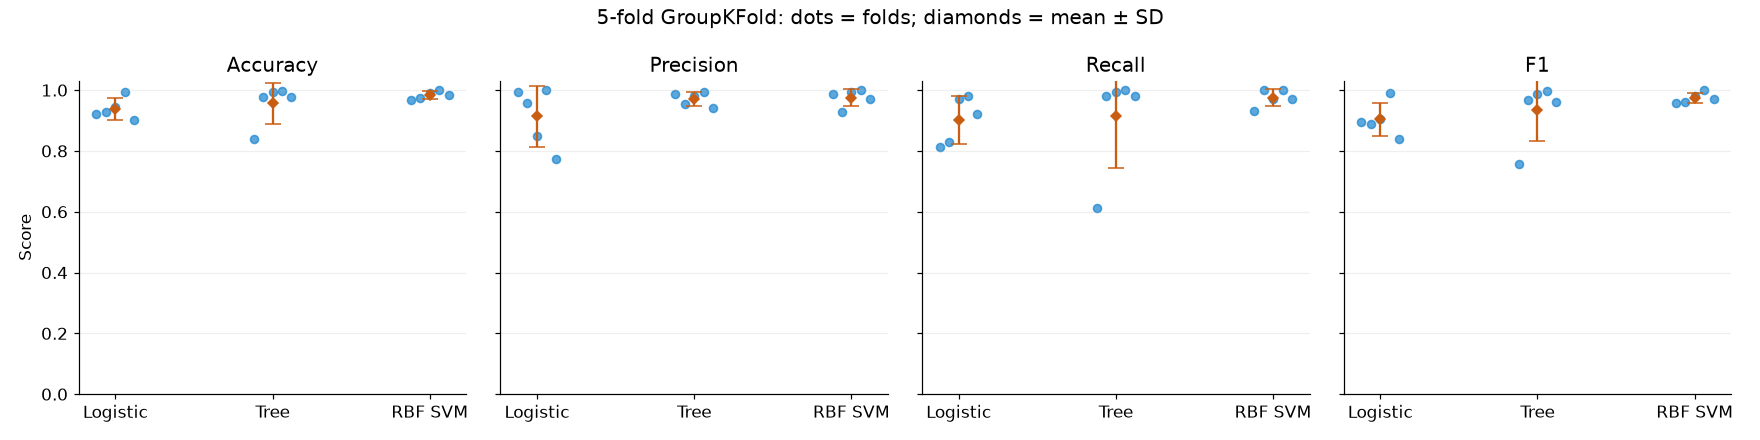

In [13]:
metric_names = ['Accuracy', 'Precision', 'Recall', 'Specificity', 'F1',
                'Balanced accuracy', 'ROC-AUC', 'Average precision']
cv_summary = cv_results.groupby('Model', sort=False)[metric_names].agg(['mean', 'std'])
formatted = pd.DataFrame(index=cv_summary.index)
for metric in metric_names:
    formatted[metric] = [f'{mean:.4f} ± {std:.4f}'
                         for mean, std in cv_summary[metric].to_numpy()]
display(formatted)
print(formatted[['Accuracy', 'Precision', 'Recall', 'F1']].to_string())
cv_summary.to_csv(OUT / 'cv_mean_std.csv')
formatted.to_csv(OUT / 'cv_mean_std_formatted.csv')

fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
for ax, metric in zip(axes, ['Accuracy', 'Precision', 'Recall', 'F1']):
    for index, name in enumerate(models):
        values = cv_results.loc[cv_results.Model == name, metric].to_numpy()
        offsets = np.linspace(-0.12, 0.12, len(values))
        ax.scatter(index + offsets, values, alpha=0.7, color='#1783cf', s=28)
        ax.errorbar(index, values.mean(), yerr=values.std(ddof=1), fmt='D',
                    color='#c95e13', capsize=5, markersize=5)
    ax.set(title=metric, xticks=[0, 1, 2], xticklabels=['Logistic', 'Tree', 'RBF SVM'],
           ylim=(0, 1.03))
    ax.grid(axis='y', alpha=0.2)
axes[0].set_ylabel('Score')
fig.suptitle(f'{n_splits}-fold GroupKFold: dots = folds; diamonds = mean ± SD')
fig.tight_layout()
fig.savefig(OUT / 'cv_metric_variability.png', dpi=180, bbox_inches='tight')
plt.show()

#### 評価用の予測を集めた混同行列 / Confusion matrices from out-of-fold predictions

各窓について、その窓の人物を学習に使わなかったモデルの予測だけを集めます。これをout-of-fold（OOF）予測と呼びます。以下はその予測を全分割で合計した混同行列です。単一の学習済みモデルによる予測ではありません。
For each window, we collect the prediction from the model trained without that participant. These are out-of-fold (OOF) predictions. The matrices pool these predictions across folds; they do not represent a single fitted model.

この集計は窓の数による重みづけになります。窓の数が異なる各分割の指標を同じ重みで平均した表とは、値が一致しない場合があります。記録の長い人物ほど影響が大きくなる点にも注意してください。
Pooled metrics weight individual windows equally. They may differ from the equally weighted fold means above, particularly when fold sizes differ. People with longer recordings have greater influence on pooled metrics.

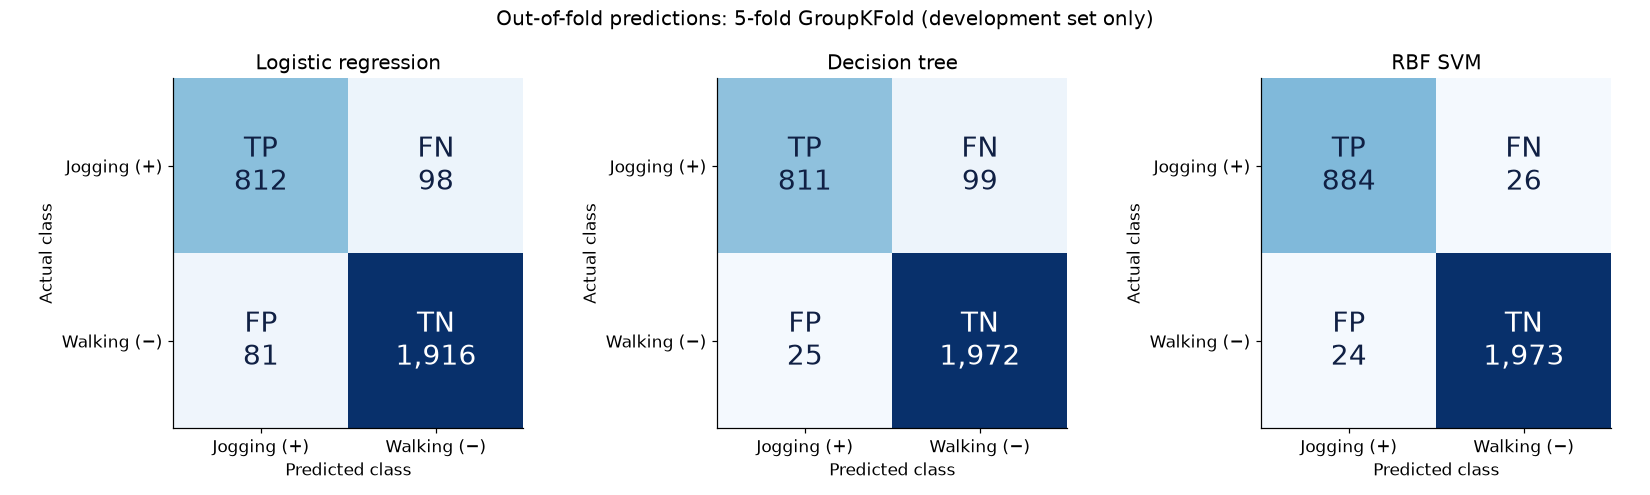

,Accuracy,Precision,Recall,Specificity,F1,Balanced accuracy
Model,,,,,,
Logistic regression,0.9384,0.9093,0.8923,0.9594,0.9007,0.9259
Decision tree,0.9573,0.9701,0.8912,0.9875,0.9290,0.9393
RBF SVM,0.9828,0.9736,0.9714,0.9880,0.9725,0.9797


In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
oof_table = cv_data[['person', 'activity', 'segment', 'start_s', 'target']].copy()
oof_table['fold'] = oof_fold
pooled_rows = []
for ax, (name, predicted) in zip(axes, oof_prediction.items()):
    cm, metrics = evaluate(cv_data.target, predicted)
    plot_matrix(cm, name, ax)
    # 分割別の件数を合計した値と照合 / Verify pooled counts against the sum over folds.
    counts = cv_results.loc[cv_results.Model == name, ['TP', 'FN', 'FP', 'TN']].sum().to_numpy()
    assert np.array_equal(cm.ravel(), counts)
    pooled_rows.append({'Model': name, **metrics})
    oof_table[name + ' prediction'] = predicted
fig.suptitle(f'Out-of-fold predictions: {n_splits}-fold GroupKFold (development set only)')
fig.tight_layout()
fig.savefig(OUT / 'cv_oof_confusion_matrices.png', dpi=180, bbox_inches='tight')
plt.show()
pooled_metrics = pd.DataFrame(pooled_rows).set_index('Model')
display(pooled_metrics.round(4))
pooled_metrics.to_csv(OUT / 'cv_oof_pooled_metrics.csv')
oof_table.to_csv(OUT / 'cv_oof_predictions.csv', index=False)

### テスト結果を比較する / Compare test results

陽性はすべて Jogging です。正解率だけでなく、見逃しFN、誤検出FP、適合率、再現率、F1を比較します。単一の分割による結果なので、モデル間の差をそのまま一般的な優劣と解釈しないでください。
Jogging is the positive class for every model. Compare misses (FN), false alarms (FP), precision, recall, and F1 as well as accuracy. These results come from one split and do not establish a universal ranking of the models.

ここでは先ほどtrainingで学習した3モデルをそのまま評価します。交差検証のモデルは各分割専用であり、ここで使うモデルを置き換えません。
The test comparison below retains the models fitted on the earlier training set. Fold-specific CV models do not replace them.


                     Accuracy  Precision  Recall      F1  FP  FN
Model                                                           
Logistic regression    0.9668     0.9694  0.9314  0.9500   6  14
Decision tree          0.9287     0.8546  0.9510  0.9002  33  10
RBF SVM                0.9602     0.9206  0.9657  0.9426  17   7


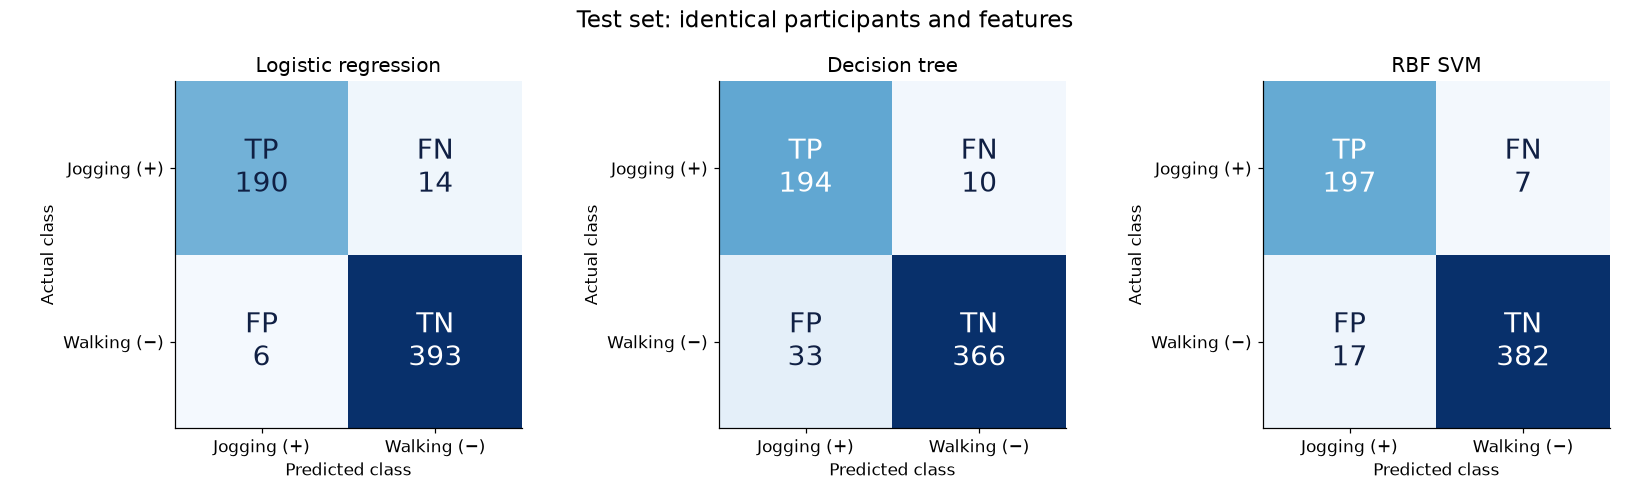

,Accuracy,Precision,Recall,Specificity,F1,Balanced accuracy,ROC-AUC,Average precision,TP,FN,FP,TN
Model,,,,,,,,,,,,
Logistic regression,0.9668,0.9694,0.9314,0.9850,0.9500,0.9582,0.9868,0.9819,190,14,6,393
Decision tree,0.9287,0.8546,0.9510,0.9173,0.9002,0.9341,0.9490,0.9488,194,10,33,366
RBF SVM,0.9602,0.9206,0.9657,0.9574,0.9426,0.9615,0.9602,0.9367,197,7,17,382


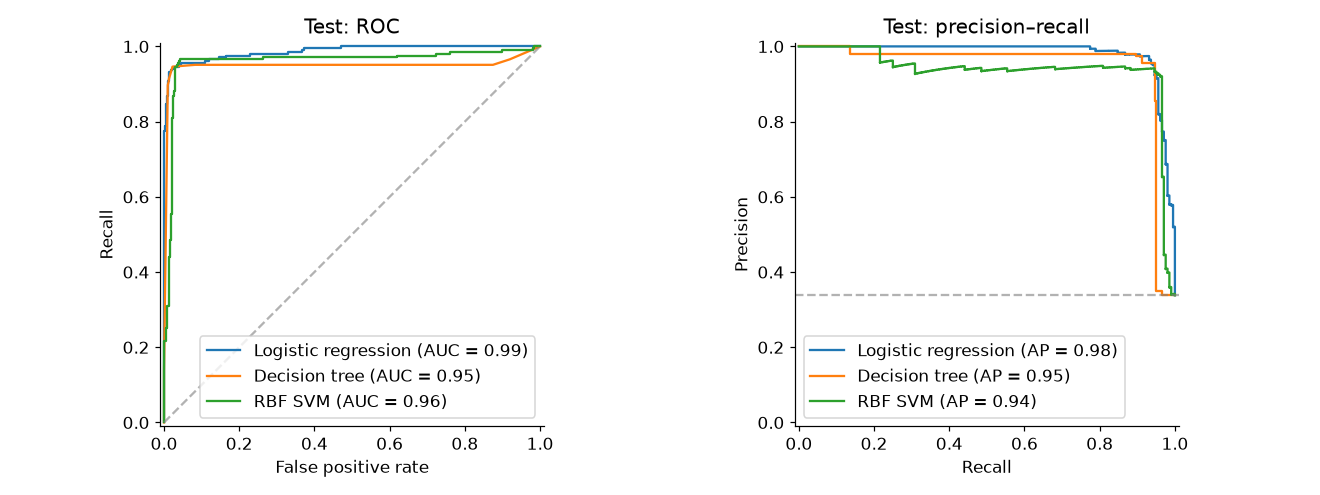

In [15]:
test_rows = []
comparison_predictions = test[['person', 'activity', 'segment', 'start_s', 'target']].copy()
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (name, estimator) in zip(axes, models.items()):
    predicted = estimator.predict(test[FEATURES])
    score = ranking_score(estimator, test[FEATURES])
    cm, metrics = evaluate(test.target, predicted)
    test_rows.append({'Model': name, **metrics,
        'ROC-AUC': roc_auc_score(test.target, score),
        'Average precision': average_precision_score(test.target, score),
        'TP': int(cm[0, 0]), 'FN': int(cm[0, 1]),
        'FP': int(cm[1, 0]), 'TN': int(cm[1, 1])})
    plot_matrix(cm, name, ax)
    comparison_predictions[name + ' prediction'] = predicted
    comparison_predictions[name + ' score'] = score
fig.suptitle('Test set: identical participants and features', fontsize=15)
fig.tight_layout()
fig.savefig(OUT / 'model_comparison_confusion_matrices.png', dpi=180, bbox_inches='tight')
plt.show()
test_comparison = pd.DataFrame(test_rows).set_index('Model')
display(test_comparison.round(4))
print(test_comparison[['Accuracy', 'Precision', 'Recall', 'F1', 'FP', 'FN']].round(4).to_string())
test_comparison.to_csv(OUT / 'model_comparison_test.csv')
comparison_predictions.to_csv(OUT / 'model_comparison_predictions.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name, estimator in models.items():
    score = ranking_score(estimator, test[FEATURES])
    RocCurveDisplay.from_predictions(test.target, score, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(test.target, score, name=name, ax=axes[1])
axes[0].plot([0, 1], [0, 1], '--', color='gray', alpha=0.6)
axes[0].set(title='Test: ROC', xlabel='False positive rate', ylabel='Recall')
axes[1].axhline(test.target.mean(), ls='--', color='gray', alpha=0.6)
axes[1].set(title='Test: precision–recall', xlabel='Recall', ylabel='Precision')
fig.tight_layout()
fig.savefig(OUT / 'model_comparison_roc_pr.png', dpi=180, bbox_inches='tight')
plt.show()

## 10. 考えてみましょう / Questions to explore

1. しきい値を下げると、FP と FN はどう変わりましたか？ / How did FP and FN change when you lowered the threshold?
2. 「すべて歩行」のモデルで、正解率だけを見ると何を見落としますか？ / What does accuracy hide for the always-walking baseline?
3. ジョギングの見逃しを減らしたいとき、どの指標を重視しますか？ / Which metric matters when missing jogging is costly?
4. 同じ人の窓をランダムに分けた評価と、未知の人での評価は、何が違うでしょうか？ / How does splitting windows differ from testing on unseen people?

このデモは歩行とジョギングの二択です。階段、静止、乗車などを入力しても正しく判定できるとは限りません。特徴量、装着位置、人物、クラスの割合が変われば性能も変わります。より厳密に検討するなら、人物をグループとする交差検証を development データに適用し、最終テストは残しておきます。
This is a two-class demonstration, not a detector for all activities. Performance can change with features, phone placement, participants, and class prevalence. For a more thorough study, use grouped cross-validation on development data while keeping a final test set untouched.

出力画像とCSVは左側のファイル欄の `classification_outputs` に保存されます。
Plots and CSV results are saved in `classification_outputs`, accessible from Colab's Files panel.

In [16]:
# @title 結果をまとめる / Package the results
import shutil
archive_path = shutil.make_archive('classification_results', 'zip', OUT)
print('Saved:', archive_path)
# Colabではファイル欄からダウンロード / Download from the Files panel in Colab.

Saved:


## 付録：生データからの再作成（任意） / Appendix: reproduce the features (optional)

通常のデモ実行では不要です。下のチェックを有効にすると公式のアーカイブをダウンロードし、同梱した特徴量と同じ前処理を実行して照合します。インターネット接続が必要です。前処理を変更するときは、モデルの評価も初めからやり直す必要があります。

This step is optional. Enable the checkbox to download the official archive, repeat preprocessing, and compare the result with the embedded feature table. Internet access is required. If you change preprocessing, repeat model development and evaluation from the beginning.

In [17]:
# @title 生データから再作成 / Rebuild from raw data
rebuild_from_raw = False # @param {type:"boolean"}

import io
import tarfile
import numpy as np
import pandas as pd

def extract_features(archive_path):
    # 配布ファイルをメモリ上で読む / Read archive members without extracting paths.
    with tarfile.open(archive_path) as archive:
        raw = archive.extractfile('WISDM_ar_v1.1/WISDM_ar_v1.1_raw.txt').read().decode()
        readme = archive.extractfile('WISDM_ar_v1.1/readme.txt').read().decode()
    rows = []
    malformed = 0
    for order, record in enumerate(raw.split(';')):
        fields = record.strip().split(',')
        if len(fields) != 6:
            malformed += bool(record.strip())
            continue
        if fields[1] not in ('Walking', 'Jogging'):
            continue
        try:
            person, activity, stamp, x, y, z = fields
            row = (order, int(person), activity, int(stamp), float(x), float(y), float(z))
            if row[3] > 0 and np.isfinite(row[4:]).all():
                rows.append(row)
        except ValueError:
            malformed += 1
    frame = pd.DataFrame(rows, columns=['order', 'person', 'activity', 'stamp', 'x', 'y', 'z'])
    # 人物・活動・記録の切れ目をまたがない / Never cross people, activities, or recording gaps.
    dt = frame.stamp.diff() / 1e9
    boundary = ((frame.person != frame.person.shift()) |
                (frame.activity != frame.activity.shift()) |
                (frame.order.diff() != 1) | (dt <= 0) | (dt > 0.25))
    frame['segment'] = boundary.cumsum()
    features, examples = [], {}
    for segment, group in frame.groupby('segment', sort=False):
        time = (group.stamp.to_numpy() - group.stamp.iloc[0]) / 1e9
        xyz = group[['x', 'y', 'z']].to_numpy()
        person, activity = int(group.person.iloc[0]), group.activity.iloc[0]
        # 5秒の重なりのない窓。20 Hzの時間軸へ補間 / Non-overlapping 5 s windows; interpolate to 20 Hz.
        for start in np.arange(0, max(0, time[-1] - 4.95), 5):
            mask = (time >= start) & (time < start + 5)
            if mask.sum() < 40:
                continue
            grid = start + np.arange(100) / 20
            magnitude = np.linalg.norm(np.column_stack([
                np.interp(grid, time, xyz[:, axis]) for axis in range(3)]), axis=1)
            centered = magnitude - magnitude.mean()
            frequency = np.fft.rfftfreq(100, d=1 / 20)
            power = abs(np.fft.rfft(centered * np.hanning(100))) ** 2
            band = (frequency >= 0.5) & (frequency <= 4.0)
            dominant = float(frequency[band][np.argmax(power[band])])
            features.append([person, activity, int(segment), float(start),
                             float(centered.std()), dominant])
            examples.setdefault(f'{person}_{activity}', centered.round(6).tolist())
    result = pd.DataFrame(features, columns=['person', 'activity', 'segment', 'start_s',
                                             'variation', 'frequency_hz'])
    stats = {'valid_walk_jog_samples': len(frame), 'malformed_records_all_activities': int(malformed),
             'windows': len(result), 'people': int(result.person.nunique())}
    return result, examples, readme, stats


if rebuild_from_raw:
    import urllib.request
    source = 'https://www.cis.fordham.edu/wisdm/includes/datasets/latest/WISDM_ar_latest.tar.gz'
    raw_archive = OUT / 'WISDM_ar_latest.tar.gz'
    urllib.request.urlretrieve(source, raw_archive)
    rebuilt, _, original_readme, stats = extract_features(raw_archive)
    pd.testing.assert_frame_equal(rebuilt, data.drop(columns='target'), check_exact=False,
                                  rtol=1e-9, atol=1e-9)
    rebuilt.to_csv(OUT / 'rebuilt_features.csv', index=False)
    (OUT / 'readme.txt').write_text(original_readme, encoding='utf-8')
    print('Reproduction check passed:', stats)
else:
    print('Skipped: the embedded data are ready to use.')

Skipped: the embedded data are ready to use.
